In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
housingdf = pd.read_csv('/Users/olubunmi/Desktop/Housing_EDA/Data/processed/house.csv')
#housingdf.shape
housingdf.head(10)

,Id,MSSubClass,MSZoning,LotArea,Utilities,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,...,KitchenQual,TotRmsAbvGrd,Functional,GarageYrBlt,GarageCars,GarageCond,Fence,MoSold,YrSold,SalePrice
0,1,60,RL,8450,AllPub,CollgCr,1Fam,2Story,7,5,...,Gd,8,Typ,2003.0,2,TA,NaN,2,2008,208500
1,2,20,RL,9600,AllPub,Veenker,1Fam,1Story,6,8,...,TA,6,Typ,1976.0,2,TA,NaN,5,2007,181500
2,3,60,RL,11250,AllPub,CollgCr,1Fam,2Story,7,5,...,Gd,6,Typ,2001.0,2,TA,NaN,9,2008,223500
3,4,70,RL,9550,AllPub,Crawfor,1Fam,2Story,7,5,...,Gd,7,Typ,1998.0,3,TA,NaN,2,2006,140000
4,5,60,RL,14260,AllPub,NoRidge,1Fam,2Story,8,5,...,Gd,9,Typ,2000.0,3,TA,NaN,12,2008,250000
5,6,50,RL,14115,AllPub,Mitchel,1Fam,1.5Fin,5,5,...,TA,5,Typ,1993.0,2,TA,MnPrv,10,2009,143000
6,7,20,RL,10084,AllPub,Somerst,1Fam,1Story,8,5,...,Gd,7,Typ,2004.0,2,TA,NaN,8,2007,307000
7,8,60,RL,10382,AllPub,NWAmes,1Fam,2Story,7,6,...,TA,7,Typ,1973.0,2,TA,NaN,11,2009,200000
8,9,50,RM,6120,AllPub,OldTown,1Fam,1.5Fin,7,5,...,TA,8,Min1,1931.0,2,TA,NaN,4,2008,129900
9,10,190,RL,7420,AllPub,BrkSide,2fmCon,1.5Unf,5,6,...,TA,5,Typ,1939.0,1,TA,NaN,1,2008,118000


In [31]:
housingdf.count()

Id              1460
MSSubClass      1460
MSZoning        1460
LotArea         1460
Utilities       1460
Neighborhood    1460
BldgType        1460
HouseStyle      1460
OverallQual     1460
OverallCond     1460
YearBuilt       1460
YearRemodAdd    1460
BsmtQual        1423
BsmtCond        1423
TotalBsmtSF     1460
Heating         1460
HeatingQC       1460
CentralAir      1460
BsmtFullBath    1460
BsmtHalfBath    1460
FullBath        1460
HalfBath        1460
BedroomAbvGr    1460
KitchenAbvGr    1460
KitchenQual     1460
TotRmsAbvGrd    1460
Functional      1460
GarageYrBlt     1379
GarageCars      1460
GarageCond      1379
Fence            281
MoSold          1460
YrSold          1460
SalePrice       1460
dtype: int64

## **Question 1: What is the correlation between the neighborhood and the price of the house sold? If any.**

In [153]:
housingdf[['Neighborhood', 'SalePrice']]
nhood_df = housingdf.groupby('Neighborhood')
mostexpensive_nhood_df = nhood_df.mean('SalePrice')[['SalePrice']].round(2).sort_values(by = 'SalePrice', ascending = False)
mostexpensive_nhood_df



,SalePrice
Neighborhood,
NoRidge,335295.32
NridgHt,316270.62
StoneBr,310499.00
Timber,242247.45
Veenker,238772.73
Somerst,225379.84
ClearCr,212565.43
Crawfor,210624.73
CollgCr,197965.77


In [155]:
nhood_stats = housingdf.groupby('Neighborhood')['SalePrice'].agg( mean='mean', median='median', count='count').round(2).sort_values(by='mean', ascending=False)
print(nhood_stats)

                   mean    median  count
Neighborhood                            
NoRidge       335295.32  301500.0     41
NridgHt       316270.62  315000.0     77
StoneBr       310499.00  278000.0     25
Timber        242247.45  228475.0     38
Veenker       238772.73  218000.0     11
Somerst       225379.84  225500.0     86
ClearCr       212565.43  200250.0     28
Crawfor       210624.73  200624.0     51
CollgCr       197965.77  197200.0    150
Blmngtn       194870.88  191000.0     17
Gilbert       192854.51  181000.0     79
NWAmes        189050.07  182900.0     73
SawyerW       186555.80  179900.0     59
Mitchel       156270.12  153500.0     49
NAmes         145847.08  140000.0    225
NPkVill       142694.44  146000.0      9
SWISU         142591.36  139500.0     25
Blueste       137500.00  137500.0      2
Sawyer        136793.14  135000.0     74
OldTown       128225.30  119000.0    113
Edwards       128219.70  121750.0    100
BrkSide       124834.05  124300.0     58
BrDale        10

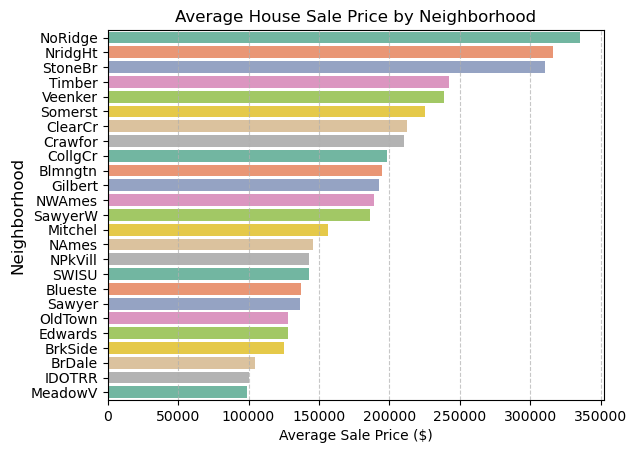

In [177]:
sns.barplot(y=nhood_stats.index, x=nhood_stats['mean'], hue=nhood_stats.index, palette='Set2', legend=False)

plt.title('Average House Sale Price by Neighborhood')
plt.xlabel('Average Sale Price ($)')
plt.ylabel('Neighborhood', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig('average_price_by_neighborhood.png')
plt.show()